<a href="https://colab.research.google.com/github/Itz-Charan/FOREST_FIRE_CLASSIFICATION_PROJ/blob/main/AIDLPROJECT_FOREST_FIRE_WITH_SIMPLE_MODELS_COMPARISON_(final).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [ ]:
!pip install -q kagglehub torch torchvision scikit-learn seaborn matplotlib pillow

IMPORT REQUIRED LIBRARIES

In [ ]:
import os
import random
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully")

Libraries imported successfully


CHECK PYTORCH AND GPU

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: Tesla T4


DOWNLOAD DATASET FROM KAGGLE

In [ ]:
import kagglehub

path = kagglehub.dataset_download(
    "obulisainaren/forest-fire-c4"
)

print("Dataset downloaded to:")
print(path)

100%|██████████| 123M/123M [00:01<00:00, 95.9MB/s]

Extracting files...


Dataset downloaded to:
/root/.cache/kagglehub/datasets/obulisainaren/forest-fire-c4/versions/2


In [ ]:
import os

for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        for file in files[:10]:
            print("  " * (level + 1) + file)

2/
  README.md
  Forect Fire/
    Forest Fire_Dataset/
    Forest Fire_Tester/
      14.jpg
      12.jpg
      abc223.jpg
      17.jpg
      3.jpg
      abc192.jpg
      4.jpg
      7.jpg
      18.jpg
      11.jpg


In [ ]:
def find_folder(base_path, possible_names):
    for root, dirs, files in os.walk(base_path):
        for d in dirs:
            if d.lower() in possible_names:
                return os.path.join(root, d)
    return None


train_dir = find_folder(
    path,
    {"train", "training"}
)

valid_dir = find_folder(
    path,
    {"valid", "validation", "val"}
)

test_dir = find_folder(
    path,
    {"test", "testing"}
)

print("Train:", train_dir)
print("Validation:", valid_dir)
print("Test:", test_dir)

Train: /root/.cache/kagglehub/datasets/obulisainaren/forest-fire-c4/versions/2/Forect Fire/Forest Fire_Dataset/train
Validation: /root/.cache/kagglehub/datasets/obulisainaren/forest-fire-c4/versions/2/Forect Fire/Forest Fire_Dataset/val
Test: /root/.cache/kagglehub/datasets/obulisainaren/forest-fire-c4/versions/2/Forect Fire/Forest Fire_Dataset/test


CHECK IMAGE CLASSES

In [ ]:
print("Train classes:")

train_classes = sorted([
    d for d in os.listdir(train_dir)
    if os.path.isdir(os.path.join(train_dir, d))
])

print(train_classes)

Train classes:
['fire', 'nofire', 'smoke', 'smokefire']


COUNT IMAGES IN EACH CLASS

In [ ]:
def count_images(folder):
    counts = {}

    for cls in sorted(os.listdir(folder)):
        cls_path = os.path.join(folder, cls)

        if os.path.isdir(cls_path):
            count = 0

            for root, dirs, files in os.walk(cls_path):
                count += len([
                    f for f in files
                    if f.lower().endswith(
                        (".jpg", ".jpeg", ".png", ".bmp", ".webp")
                    )
                ])

            counts[cls] = count

    return counts


train_counts = count_images(train_dir)

print("Training images:")
print(train_counts)

if valid_dir:
    print("\nValidation images:")
    print(count_images(valid_dir))

if test_dir:
    print("\nTest images:")
    print(count_images(test_dir))

Training images:
{'fire': 800, 'nofire': 800, 'smoke': 800, 'smokefire': 800}

Validation images:
{'fire': 200, 'nofire': 200, 'smoke': 200, 'smokefire': 200}

Test images:
{'fire': 200, 'nofire': 200, 'smoke': 200, 'smokefire': 200}


VISUALIZE CLASS DISTRIBUTION

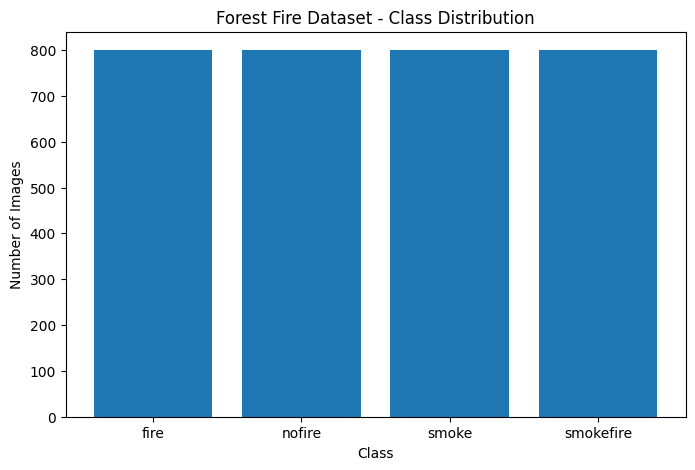

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    train_counts.keys(),
    train_counts.values()
)

plt.title("Forest Fire Dataset - Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.show()

DISPLAY SAMPLE IMAGES

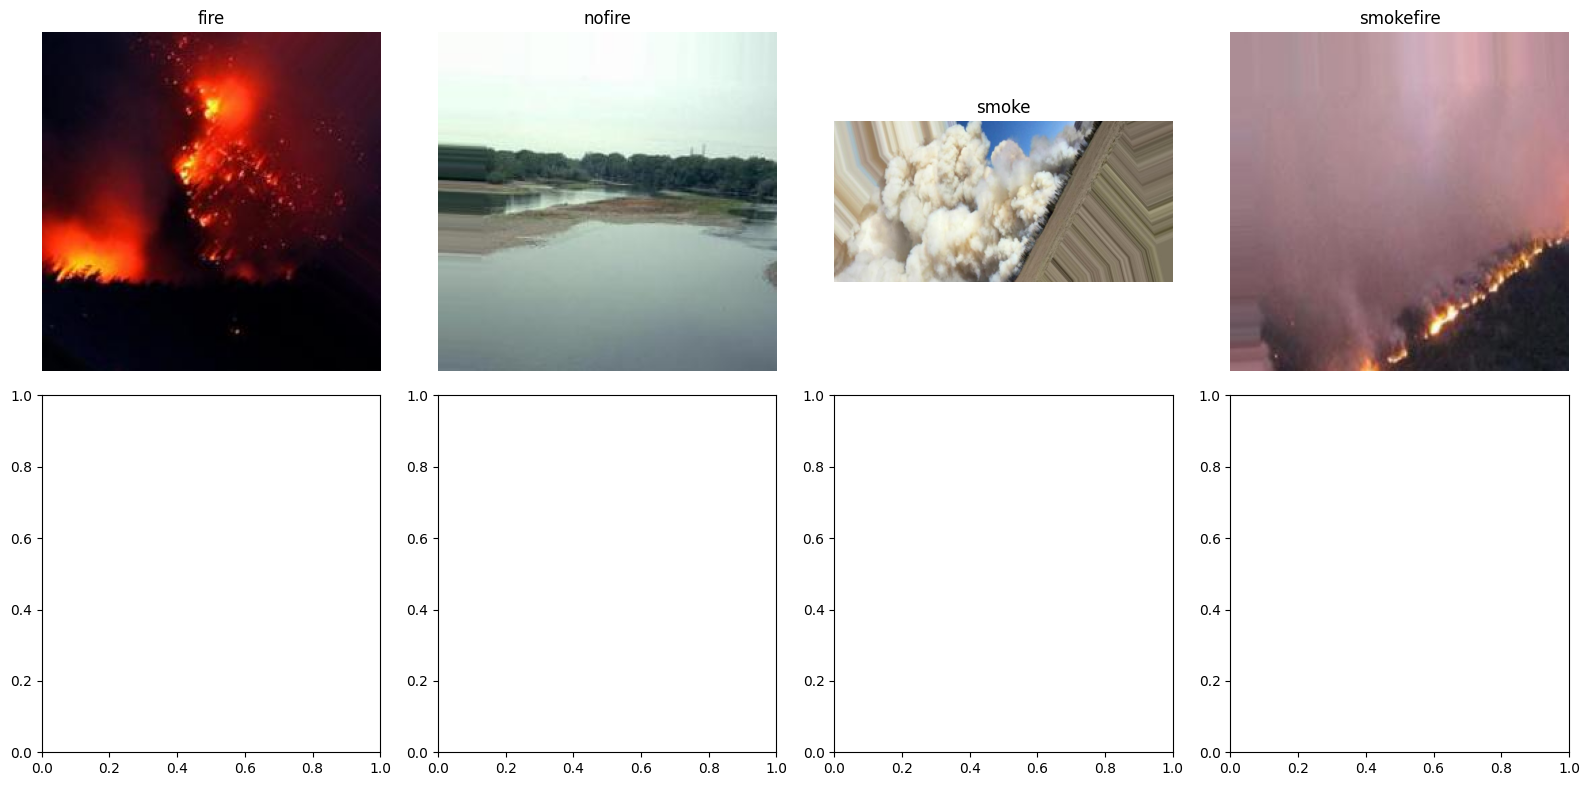

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, cls in zip(axes.flatten(), train_classes):

    cls_path = os.path.join(train_dir, cls)

    images = [
        f for f in os.listdir(cls_path)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    ]

    image_file = random.choice(images)
    image_path = os.path.join(cls_path, image_file)

    image = Image.open(image_path).convert("RGB")

    ax.imshow(image)
    ax.set_title(cls)
    ax.axis("off")

plt.tight_layout()
plt.show()

CHECK IMAGE DIMENSIONS

In [ ]:
sample_class = train_classes[0]

sample_folder = os.path.join(train_dir, sample_class)

sample_images = [
    f for f in os.listdir(sample_folder)
    if f.lower().endswith(
        (".jpg", ".jpeg", ".png", ".bmp", ".webp")
    )
]

sample_image_path = os.path.join(
    sample_folder,
    sample_images[0]
)

img = Image.open(sample_image_path)

print("Image size:", img.size)
print("Image mode:", img.mode)

Image size: (250, 250)
Image mode: RGB


DEFINE IMAGE SIZE AND BATCH SIZE

In [ ]:
IMG_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.1),

    transforms.RandomRotation(15),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05
    ),

    transforms.RandomResizedCrop(
        IMG_SIZE,
        scale=(0.85, 1.0)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


valid_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

IMAGE DATA AUGMENTATION

In [ ]:
train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

valid_dataset = datasets.ImageFolder(
    valid_dir,
    transform=valid_transform
)

print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))

print("Classes:", train_dataset.classes)
print("Class mapping:", train_dataset.class_to_idx)

Training images: 3200
Validation images: 800
Classes: ['fire', 'nofire', 'smoke', 'smokefire']
Class mapping: {'fire': 0, 'nofire': 1, 'smoke': 2, 'smokefire': 3}


LOAD IMAGE DATASETS

In [ ]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created")

DataLoaders created


CHECK IMAGE BATCH

In [ ]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels:", labels[:10])

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Labels: tensor([1, 3, 3, 0, 3, 3, 0, 0, 1, 3])


LOAD PRETRAINED EFFICIENTNET-B0

In [ ]:
weights = models.EfficientNet_B0_Weights.DEFAULT

model = models.efficientnet_b0(
    weights=weights
)

print(model)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 105MB/s]

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

MODIFY FINAL CLASSIFICATION LAYER

In [ ]:
num_classes = len(train_dataset.classes)

model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    num_classes
)

model = model.to(device)

print("Number of classes:", num_classes)
print(model.classifier)

Number of classes: 4
Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=4, bias=True)
)


DEFINE LOSS FUNCTION AND DEFINE OPTIMIZER

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

print("Optimizer:", optimizer)

Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.0001
)


CREATE TRAINING FUNCTION

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

CREATE VALIDATION FUNCTION

In [ ]:
def validate(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predicted.cpu().numpy()
            )

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return (
        epoch_loss,
        epoch_accuracy,
        all_labels,
        all_predictions
    )

TRAIN THE MODEL


In [ ]:
EPOCHS = 15

best_accuracy = 0.0
patience = 5
patience_counter = 0

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, val_acc, y_true, y_pred = validate(
        model,
        valid_loader,
        criterion
    )

    scheduler.step(val_acc)

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc*100:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc*100:.2f}%"
    )

    if val_acc > best_accuracy:

        best_accuracy = val_acc

        torch.save(
            model.state_dict(),
            "/content/best_forest_fire_model.pth"
        )

        patience_counter = 0

        print("  ✓ Best model saved")

    else:
        patience_counter += 1

    if patience_counter >= patience:
        print("Early stopping triggered.")
        break

print("\nBest Validation Accuracy:")
print(f"{best_accuracy*100:.2f}%")

Epoch [1/15] Train Loss: 0.7171 Train Acc: 77.06% Val Loss: 0.2361 Val Acc: 92.12%
  ✓ Best model saved
Epoch [2/15] Train Loss: 0.2816 Train Acc: 88.94% Val Loss: 0.1494 Val Acc: 95.25%
  ✓ Best model saved
Epoch [3/15] Train Loss: 0.1945 Train Acc: 92.78% Val Loss: 0.1216 Val Acc: 96.38%
  ✓ Best model saved
Epoch [4/15] Train Loss: 0.1560 Train Acc: 94.38% Val Loss: 0.0926 Val Acc: 97.38%
  ✓ Best model saved
Epoch [5/15] Train Loss: 0.1239 Train Acc: 95.78% Val Loss: 0.0696 Val Acc: 97.88%
  ✓ Best model saved
Epoch [6/15] Train Loss: 0.0907 Train Acc: 96.94% Val Loss: 0.0633 Val Acc: 97.75%
Epoch [7/15] Train Loss: 0.0726 Train Acc: 97.81% Val Loss: 0.0568 Val Acc: 98.50%
  ✓ Best model saved
Epoch [8/15] Train Loss: 0.0916 Train Acc: 96.94% Val Loss: 0.0537 Val Acc: 98.12%
Epoch [9/15] Train Loss: 0.0545 Train Acc: 98.41% Val Loss: 0.0511 Val Acc: 98.25%
Epoch [10/15] Train Loss: 0.0579 Train Acc: 98.09% Val Loss: 0.0654 Val Acc: 97.75%
Epoch [11/15] Train Loss: 0.0453 Train Acc:

LOAD BEST MODEL

In [ ]:
model.load_state_dict(
    torch.load(
        "/content/best_forest_fire_model.pth",
        map_location=device
    )
)

model = model.to(device)

print("Best model loaded successfully")

Best model loaded successfully


FINAL VALIDATION ACCURACY

In [ ]:
val_loss, val_accuracy, y_true, y_pred = validate(
    model,
    valid_loader,
    criterion
)

print("Final Validation Accuracy:")
print(f"{val_accuracy * 100:.2f}%")

Final Validation Accuracy:
98.75%


CLASSIFICATION REPORT

In [ ]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=train_dataset.classes
    )
)

              precision    recall  f1-score   support

        fire       1.00      0.96      0.98       200
      nofire       0.99      0.99      0.99       200
       smoke       0.99      0.99      0.99       200
   smokefire       0.97      1.00      0.98       200

    accuracy                           0.99       800
   macro avg       0.99      0.99      0.99       800
weighted avg       0.99      0.99      0.99       800



CONFUSION MATRIX

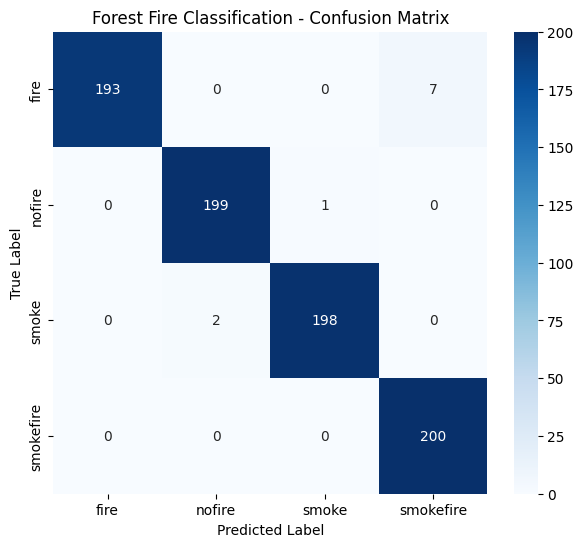

In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=train_dataset.classes,
    yticklabels=train_dataset.classes
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Forest Fire Classification - Confusion Matrix")

plt.show()

TRAINING AND VALIDATION ACCURACY GRAPH

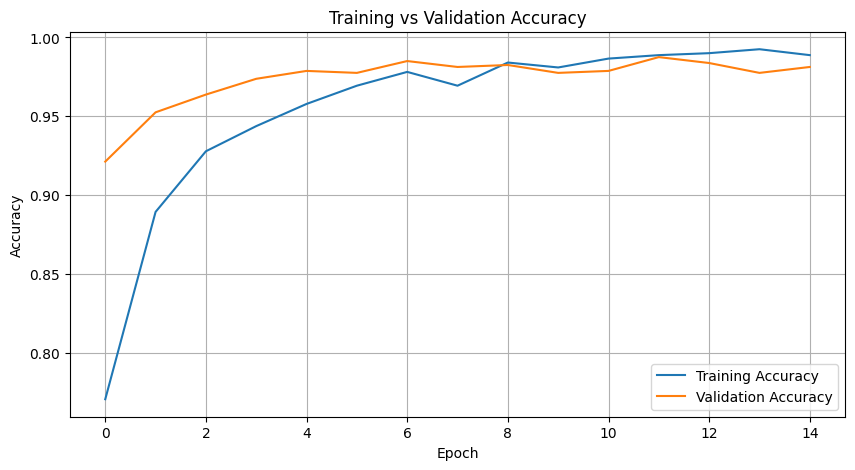

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    history["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title("Training vs Validation Accuracy")

plt.legend()
plt.grid()

plt.show()

TRAINING AND VALIDATION LOSS GRAPH

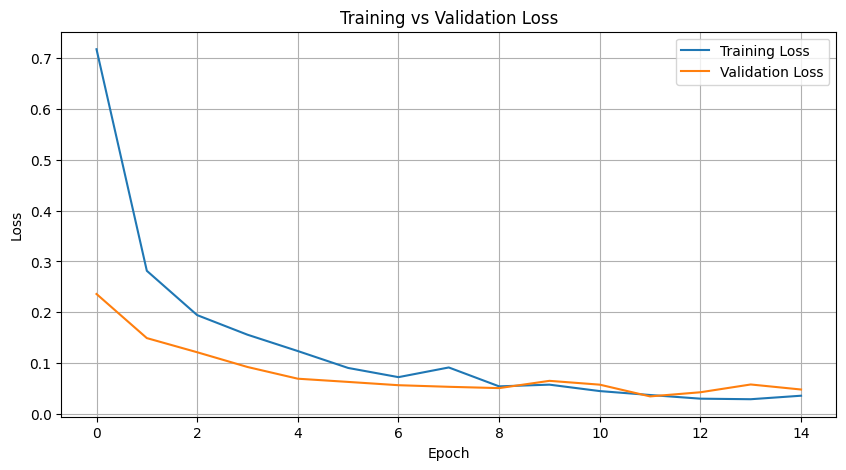

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("Training vs Validation Loss")

plt.legend()
plt.grid()

plt.show()

SAVE FINAL MODEL

In [ ]:
torch.save(
    model.state_dict(),
    "/content/forest_fire_efficientnet_b0.pth"
)

print("Model saved successfully.")

Model saved successfully.


UPLOAD AN IMAGE AND PREDICT


In [ ]:
from google.colab import files

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

print("Uploaded:", image_path)

Saving smokefire_test_1007.jpg to smokefire_test_1007.jpg
Uploaded: smokefire_test_1007.jpg


PREDICTION OF THE IMAGE

Prediction: smokefire
Confidence: 99.46%


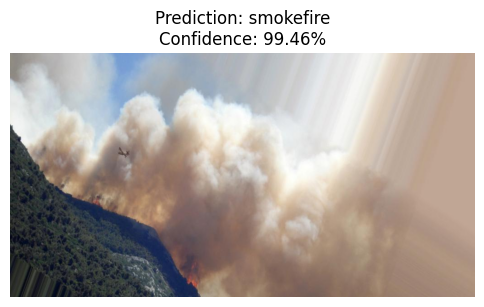

In [ ]:
model.eval()

image = Image.open(image_path).convert("RGB")

image_tensor = valid_transform(image).unsqueeze(0)

image_tensor = image_tensor.to(device)

with torch.no_grad():

    output = model(image_tensor)

    probabilities = torch.softmax(
        output,
        dim=1
    )

    predicted_class = torch.argmax(
        probabilities,
        dim=1
    ).item()

confidence = probabilities[0][predicted_class].item()

predicted_label = train_dataset.classes[predicted_class]

print("Prediction:", predicted_label)
print(f"Confidence: {confidence * 100:.2f}%")

plt.figure(figsize=(6, 6))

plt.imshow(image)

plt.title(
    f"Prediction: {predicted_label}\n"
    f"Confidence: {confidence*100:.2f}%"
)

plt.axis("off")
plt.show()

DISPLAY CLASS PROBABILITIES

In [ ]:
print("Prediction probabilities:\n")

for class_name, probability in zip(
    train_dataset.classes,
    probabilities[0].cpu().numpy()
):

    print(
        f"{class_name}: "
        f"{probability*100:.2f}%"
    )

Prediction probabilities:

fire: 0.00%
nofire: 0.00%
smoke: 0.06%
smokefire: 99.94%


FINAL PROJECT RESULTS

In [ ]:
print("=" * 60)
print("FOREST FIRE IMAGE CLASSIFICATION")
print("=" * 60)

print("Model: EfficientNet-B0")
print("Transfer Learning: Yes")
print("Image Size: 224 x 224")
print("Number of Classes:", num_classes)

print(
    "Best Validation Accuracy:",
    f"{best_accuracy*100:.2f}%"
)

print(
    "Final Validation Accuracy:",
    f"{val_accuracy*100:.2f}%"
)

print("=" * 60)

FOREST FIRE IMAGE CLASSIFICATION
Model: EfficientNet-B0
Transfer Learning: Yes
Image Size: 224 x 224
Number of Classes: 4
Best Validation Accuracy: 98.75%
Final Validation Accuracy: 98.75%


# Additional Simple Models and Model Comparison

This section adds three easy-to-understand image-classification models to compare with the existing EfficientNet-B0 and YOLO classification models:

1. **Simple CNN** — a small convolutional neural network trained from scratch.
2. **ResNet18** — a compact residual network using pretrained weights.
3. **MobileNetV2** — a lightweight network designed for efficient inference.

Run this section after the original dataset, `train_loader`, `valid_loader`, `device`, and `train_one_epoch` / `validate` cells have run. For a fair comparison, all PyTorch models use the same train/validation split and image size. The comparison table is filled with measured results when you run the cells; no accuracy values are invented.


In [ ]:
import time
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

NUM_CLASSES = len(train_dataset.classes)
SIMPLE_MODEL_EPOCHS = 5  # Increase to 10-15 if time/GPU allows

class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

def build_resnet18(num_classes):
    try:
        net = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    except Exception as e:
        print("Pretrained ResNet18 weights unavailable; using random initialization:", e)
        net = models.resnet18(weights=None)
    net.fc = nn.Linear(net.fc.in_features, num_classes)
    return net

def build_mobilenet_v2(num_classes):
    try:
        net = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
    except Exception as e:
        print("Pretrained MobileNetV2 weights unavailable; using random initialization:", e)
        net = models.mobilenet_v2(weights=None)
    net.classifier[1] = nn.Linear(net.classifier[1].in_features, num_classes)
    return net

def run_model_experiment(model_name, net, epochs=SIMPLE_MODEL_EPOCHS):
    net = net.to(device)
    loss_fn = nn.CrossEntropyLoss()
    opt = optim.Adam(net.parameters(), lr=0.001 if model_name == "Simple CNN" else 0.0001)
    best_acc = 0.0
    best_true, best_pred = [], []
    start = time.perf_counter()

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(net, train_loader, loss_fn, opt)
        val_loss, val_acc, y_true_model, y_pred_model = validate(net, valid_loader, loss_fn)
        print(f"{model_name} | Epoch {epoch+1}/{epochs} | "
              f"Train acc: {train_acc*100:.2f}% | Val acc: {val_acc*100:.2f}%")
        if val_acc > best_acc:
            best_acc = val_acc
            best_true, best_pred = y_true_model, y_pred_model
            torch.save(net.state_dict(), f"/content/{model_name.lower().replace(' ', '_')}_best.pth")

    elapsed = time.perf_counter() - start
    return {
        "Model": model_name,
        "Split": "Validation",
        "Images": len(best_true),
        "Accuracy (%)": round(100 * accuracy_score(best_true, best_pred), 2),
        "Macro precision": round(precision_score(best_true, best_pred, average="macro", zero_division=0), 4),
        "Macro recall": round(recall_score(best_true, best_pred, average="macro", zero_division=0), 4),
        "Macro F1": round(f1_score(best_true, best_pred, average="macro", zero_division=0), 4),
        "Training time (seconds)": round(elapsed, 2)
    }

simple_model_results = []
simple_models = [
    ("Simple CNN", SimpleCNN(NUM_CLASSES)),
    ("ResNet18", build_resnet18(NUM_CLASSES)),
    ("MobileNetV2", build_mobilenet_v2(NUM_CLASSES))
]

for model_name, net in simple_models:
    print("\n" + "="*55 + "\nTraining:", model_name)
    simple_model_results.append(run_model_experiment(model_name, net))

simple_models_df = pd.DataFrame(simple_model_results)
display(simple_models_df)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 170MB/s]


Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 128MB/s]


Training: Simple CNN


Simple CNN | Epoch 1/5 | Train acc: 60.09% | Val acc: 71.62%
Simple CNN | Epoch 2/5 | Train acc: 70.12% | Val acc: 76.75%
Simple CNN | Epoch 3/5 | Train acc: 75.12% | Val acc: 79.12%
Simple CNN | Epoch 4/5 | Train acc: 76.22% | Val acc: 79.00%
Simple CNN | Epoch 5/5 | Train acc: 76.84% | Val acc: 81.88%

Training: ResNet18
ResNet18 | Epoch 1/5 | Train acc: 84.19% | Val acc: 93.62%
ResNet18 | Epoch 2/5 | Train acc: 91.84% | Val acc: 93.62%
ResNet18 | Epoch 3/5 | Train acc: 94.09% | Val acc: 96.00%
ResNet18 | Epoch 4/5 | Train acc: 95.91% | Val acc: 97.00%
ResNet18 | Epoch 5/5 | Train acc: 96.19% | Val acc: 95.88%

Training: MobileNetV2
MobileNetV2 | Epoch 1/5 | Train acc: 77.53% | Val acc: 90.12%
MobileNetV2 | Epoch 2/5 | Train acc: 88.12% | Val acc: 92.38%
MobileNetV2 | Epoch 3/5 | Train acc: 91.34% | Val acc: 93.62%
MobileNetV2 | Epoch 4/5 | Train acc: 92.84% | Val acc: 95.75%
MobileNetV2 | Epoch 5/5 | Train acc: 93.81% | Val acc: 95.88%


,Model,Split,Images,Accuracy (%),Macro precision,Macro recall,Macro F1,Training time (seconds)
0,Simple CNN,Validation,800,81.88,0.8234,0.8187,0.8122,171.71
1,ResNet18,Validation,800,97.00,0.9708,0.9700,0.9701,179.64
2,MobileNetV2,Validation,800,95.88,0.9604,0.9587,0.9585,182.92


# Additional Models: YOLO Classification

This section is added to the existing EfficientNet-B0 project; it does not replace the original model. It reuses the same Kaggle Forest Fire C4 dataset and trains YOLO classification models on the same four image classes.

**Important:** This dataset has class-labelled images, so these cells perform image classification (one class per image), not object detection with bounding boxes. YOLOv5, YOLOv8, YOLO11, and YOLO12 have classification workflows. YOLOv6, YOLOv7, YOLOv9, and YOLOv10 are not included as classifiers here because their standard official workflows are detection-focused; using them for detection would require bounding-box annotations.

## YOLO Setup — install Ultralytics

**Run order:** execute the cells in notebook order from top to bottom. The YOLOv5 validation cell is placed immediately after YOLOv5 training so its checkpoint variables exist.

In [ ]:
%pip install -q ultralytics
print("Ultralytics installation complete. If imports fail after installation, restart the runtime and run cells from the beginning.")

Ultralytics installation complete. If imports fail after installation, restart the runtime and run cells from the beginning.


## Prepare YOLO dataset paths
This uses the `train_dir`, `valid_dir`, and `test_dir` variables created earlier in this notebook. YOLO expects `train`, `val`, and optionally `test` folders, each containing one subfolder per class.

In [ ]:
from pathlib import Path
import os
import shutil
import torch
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from ultralytics import YOLO

YOLO_DATA_DIR = Path("/content/forest_fire_yolo_cls")
YOLO_DATA_DIR.mkdir(parents=True, exist_ok=True)

def replace_with_directory_link(source, destination):
    if source is None:
        return
    source = Path(source).resolve()
    destination = Path(destination)
    if not source.exists():
        raise FileNotFoundError(f"Source dataset folder not found: {source}")
    if destination.is_symlink() or destination.is_file():
        destination.unlink()
    elif destination.exists():
        shutil.rmtree(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.symlink_to(source, target_is_directory=True)

if train_dir is None or valid_dir is None:
    raise RuntimeError(
        "Could not find the dataset train/validation folders. Run the dataset download cell, "
        "inspect the folder tree, and confirm that the dataset has train and val/valid folders."
    )

replace_with_directory_link(train_dir, YOLO_DATA_DIR / "train")
replace_with_directory_link(valid_dir, YOLO_DATA_DIR / "val")
if test_dir is not None:
    replace_with_directory_link(test_dir, YOLO_DATA_DIR / "test")

print("YOLO dataset:", YOLO_DATA_DIR)
for split in ["train", "val", "test"]:
    folder = YOLO_DATA_DIR / split
    if folder.exists():
        print(split, "classes:", sorted(
            p.name for p in folder.iterdir() if p.is_dir()
        ))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLO dataset: /content/forest_fire_yolo_cls
train classes: ['fire', 'nofire', 'smoke', 'smokefire']
val classes: ['fire', 'nofire', 'smoke', 'smokefire']
test classes: ['fire', 'nofire', 'smoke', 'smokefire']


## Common training settings

In [ ]:
YOLO_EPOCHS = 15
YOLO_IMAGE_SIZE = 224
YOLO_BATCH_SIZE = 32
YOLO_PATIENCE = 5
YOLO_DEVICE = 0 if torch.cuda.is_available() else "cpu"
YOLO_RUNS_DIR = Path("/content/forest_fire_yolo_runs")
YOLO_RUNS_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", YOLO_DEVICE)
print("Epochs:", YOLO_EPOCHS)
print("Image size:", YOLO_IMAGE_SIZE)
print("Batch size:", YOLO_BATCH_SIZE)

Device: 0
Epochs: 15
Image size: 224
Batch size: 32


## YOLOv5 — install repository

YOLOv5 classification uses its repository's `classify/train.py` script. The Git URL below is plain text (not a Markdown link), which avoids the clone error caused by pasting a formatted link.

In [ ]:
import subprocess
import sys
from pathlib import Path

YOLOV5_REPO = Path("/content/yolov5")

if not (YOLOV5_REPO / "classify" / "train.py").exists():
    if YOLOV5_REPO.exists():
        shutil.rmtree(YOLOV5_REPO)
    subprocess.run([
        "git", "clone", "--depth", "1",
        "https://github.com/ultralytics/yolov5.git",
        str(YOLOV5_REPO)
    ], check=True)

print("YOLOv5 repository:", YOLOV5_REPO)

YOLOv5 repository: /content/yolov5


## YOLOv5 — train classifier

In [ ]:
# Install YOLOv5 requirements if needed.
# If this cell reports a dependency conflict, restart the runtime and run
# the YOLOv5 section in a fresh Colab runtime.
subprocess.run([
    sys.executable, "-m", "pip", "install", "-q",
    "-r", str(YOLOV5_REPO / "requirements.txt")
], check=True)

yolov5_device = "0" if torch.cuda.is_available() else "cpu"
yolov5_run_dir = YOLO_RUNS_DIR / "yolov5"

subprocess.run([
    sys.executable, str(YOLOV5_REPO / "classify" / "train.py"),
    "--model", "yolov5n-cls.pt",
    "--data", str(YOLO_DATA_DIR),
    "--epochs", str(YOLO_EPOCHS),
    "--img", str(YOLO_IMAGE_SIZE),
    "--batch-size", str(YOLO_BATCH_SIZE),
    "--device", yolov5_device,
    "--project", str(YOLO_RUNS_DIR),
    "--name", "yolov5",
    "--exist-ok"
], check=True)

YOLOV5_BEST = YOLO_RUNS_DIR / "yolov5" / "weights" / "best.pt"
print("YOLOv5 best checkpoint:", YOLOV5_BEST)

YOLOv5 best checkpoint: /content/forest_fire_yolo_runs/yolov5/weights/best.pt


## YOLOv5 — validate the trained classifier

In [ ]:
# Validate the YOLOv5 classifier after its training cell has completed.
if "YOLOV5_BEST" in globals() and Path(YOLOV5_BEST).exists():
    yolov5_val_device = "0" if torch.cuda.is_available() else "cpu"
    subprocess.run([
        sys.executable,
        str(YOLOV5_REPO / "classify" / "val.py"),
        "--weights", str(YOLOV5_BEST),
        "--data", str(YOLO_DATA_DIR),
        "--img", str(YOLO_IMAGE_SIZE),
        "--device", yolov5_val_device
    ], check=True)
else:
    print("YOLOv5 checkpoint not found; run the YOLOv5 training cell first.")

## YOLOv6, YOLOv7, YOLOv9, and YOLOv10 — compatibility note

The original project dataset contains only image-level class labels. The standard official workflows for these versions are object-detection-focused, rather than compatible pretrained classification pipelines like the classifiers below. To train these as object detectors, you would need bounding-box annotations for fire/smoke and a YOLO detection-format dataset. This project does not silently treat a detection model as a classifier.

## YOLOv8 — train classifier

In [ ]:
model_yolov8 = YOLO("yolov8n-cls.pt")

start_yolov8 = time.time()
model_yolov8.train(
    data=str(YOLO_DATA_DIR),
    epochs=YOLO_EPOCHS,
    imgsz=YOLO_IMAGE_SIZE,
    batch=YOLO_BATCH_SIZE,
    patience=YOLO_PATIENCE,
    device=YOLO_DEVICE,
    seed=42,
    project=str(YOLO_RUNS_DIR),
    name="yolov8",
    exist_ok=True,
    plots=True
)
time_yolov8 = time.time() - start_yolov8

YOLOV8_BEST = YOLO_RUNS_DIR / "yolov8" / "weights" / "best.pt"
print("YOLOv8 training time:", round(time_yolov8, 2), "seconds")
print("Best checkpoint:", YOLOV8_BEST)

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/forest_fire_yolo_cls, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8, nbs=64, nms=None, opset=None, optimize=False, op

## YOLO11 — train classifier

In [ ]:
model_yolo11 = YOLO("yolo11n-cls.pt")

start_yolo11 = time.time()
model_yolo11.train(
    data=str(YOLO_DATA_DIR),
    epochs=YOLO_EPOCHS,
    imgsz=YOLO_IMAGE_SIZE,
    batch=YOLO_BATCH_SIZE,
    patience=YOLO_PATIENCE,
    device=YOLO_DEVICE,
    seed=42,
    project=str(YOLO_RUNS_DIR),
    name="yolo11",
    exist_ok=True,
    plots=True
)
time_yolo11 = time.time() - start_yolo11

YOLO11_BEST = YOLO_RUNS_DIR / "yolo11" / "weights" / "best.pt"
print("YOLO11 training time:", round(time_yolo11, 2), "seconds")
print("Best checkpoint:", YOLO11_BEST)

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/forest_fire_yolo_cls, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11, nbs=64, nms=None, opset=None, optimize=False, op

## YOLO12 — train classifier from model configuration
This initializes the YOLO12 classification architecture from YAML rather than pretrained classification weights. Training may take longer or produce lower accuracy than pretrained models.

In [ ]:
model_yolo12 = YOLO("yolo12n-cls.yaml")

start_yolo12 = time.time()
model_yolo12.train(
    data=str(YOLO_DATA_DIR),
    epochs=YOLO_EPOCHS,
    imgsz=YOLO_IMAGE_SIZE,
    batch=YOLO_BATCH_SIZE,
    patience=YOLO_PATIENCE,
    device=YOLO_DEVICE,
    seed=42,
    project=str(YOLO_RUNS_DIR),
    name="yolo12",
    exist_ok=True,
    plots=True
)
time_yolo12 = time.time() - start_yolo12

YOLO12_BEST = YOLO_RUNS_DIR / "yolo12" / "weights" / "best.pt"
print("YOLO12 training time:", round(time_yolo12, 2), "seconds")
print("Best checkpoint:", YOLO12_BEST)

YOLO12n-cls summary: 152 layers, 2,999,496 parameters, 2,999,496 gradients, 4.6 GFLOPs
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/forest_fire_yolo_cls, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo12n-cls.yaml, momentum=0.937, m

## Evaluate trained Ultralytics classifiers
Uses the held-out `test` folder when present; otherwise it evaluates on `val`. If it falls back to validation, report the results as validation metrics rather than independent test metrics.


YOLOv8n-cls report:
              precision    recall  f1-score   support

        fire       0.94      0.67      0.78       200
      nofire       0.99      0.97      0.98       200
       smoke       0.85      0.71      0.77       200
   smokefire       0.59      0.86      0.70       200

    accuracy                           0.80       800
   macro avg       0.84      0.80      0.81       800
weighted avg       0.84      0.80      0.81       800



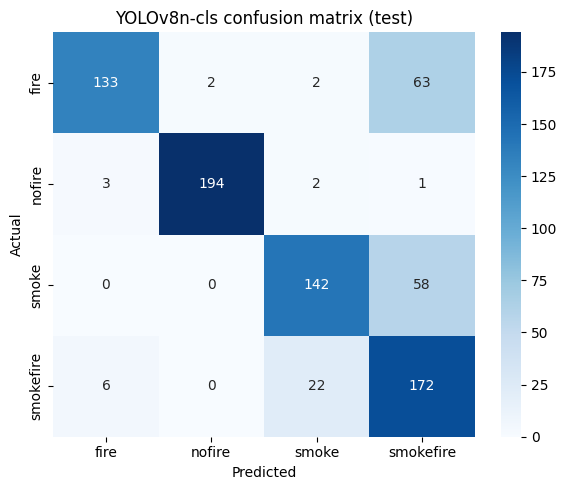


YOLO11n-cls report:
              precision    recall  f1-score   support

        fire       0.98      0.67      0.79       200
      nofire       0.99      0.97      0.98       200
       smoke       0.84      0.67      0.74       200
   smokefire       0.57      0.88      0.69       200

    accuracy                           0.80       800
   macro avg       0.85      0.80      0.80       800
weighted avg       0.85      0.80      0.80       800



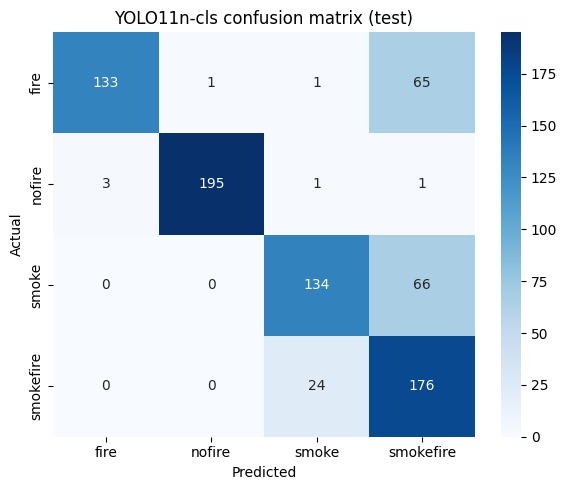


YOLO12n-cls report:
              precision    recall  f1-score   support

        fire       0.84      0.59      0.69       200
      nofire       0.91      0.89      0.90       200
       smoke       0.65      0.90      0.76       200
   smokefire       0.49      0.47      0.48       200

    accuracy                           0.71       800
   macro avg       0.72      0.71      0.71       800
weighted avg       0.72      0.71      0.71       800



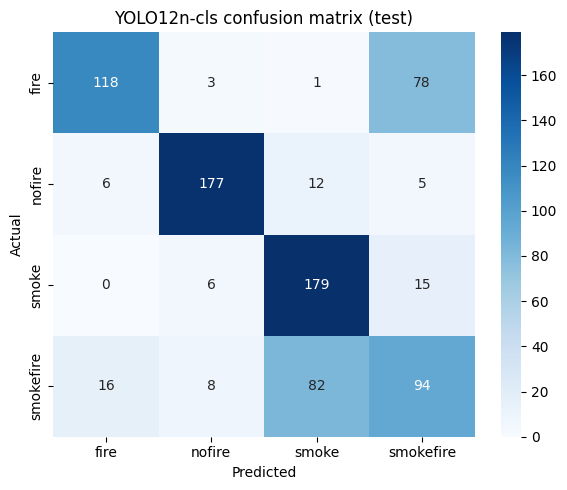

,Model,Evaluated split,Images,Accuracy (%),Macro precision,Macro recall,Macro F1,Mean inference (ms/image)
0,YOLOv8n-cls,test,800,80.12,0.8392,0.8012,0.8064,9.42
1,YOLO11n-cls,test,800,79.75,0.8454,0.7975,0.8035,11.35
2,YOLO12n-cls,test,800,71.00,0.7245,0.7100,0.7069,15.46


In [ ]:
EVAL_SPLIT = "test" if (YOLO_DATA_DIR / "test").exists() else "val"
EVAL_DIR = YOLO_DATA_DIR / EVAL_SPLIT
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def evaluate_yolo_classifier(checkpoint, model_name):
    checkpoint = Path(checkpoint)
    if not checkpoint.exists():
        print(f"Skipping {model_name}: checkpoint not found at {checkpoint}")
        return None

    classifier = YOLO(str(checkpoint))
    actual, predicted, inference_seconds = [], [], []

    for class_dir in sorted(p for p in EVAL_DIR.iterdir() if p.is_dir()):
        for image_path in class_dir.rglob("*"):
            if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
                continue

            start = time.perf_counter()
            result = classifier.predict(
                source=str(image_path),
                imgsz=YOLO_IMAGE_SIZE,
                verbose=False
            )[0]
            inference_seconds.append(time.perf_counter() - start)

            actual.append(class_dir.name)
            predicted.append(result.names[int(result.probs.top1)])

    if not actual:
        print(f"No images found in {EVAL_DIR}")
        return None

    report = classification_report(
        actual, predicted, output_dict=True, zero_division=0
    )

    row = {
        "Model": model_name,
        "Evaluated split": EVAL_SPLIT,
        "Images": len(actual),
        "Accuracy (%)": round(100 * accuracy_score(actual, predicted), 2),
        "Macro precision": round(report["macro avg"]["precision"], 4),
        "Macro recall": round(report["macro avg"]["recall"], 4),
        "Macro F1": round(report["macro avg"]["f1-score"], 4),
        "Mean inference (ms/image)": round(
            1000 * np.mean(inference_seconds), 2
        )
    }

    print(f"\n{model_name} report:")
    print(classification_report(actual, predicted, zero_division=0))

    labels = list(classifier.names.values())
    cm = confusion_matrix(actual, predicted, labels=labels)
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=labels, yticklabels=labels
    )
    plt.title(f"{model_name} confusion matrix ({EVAL_SPLIT})")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

    return row

yolo_comparison_rows = []
for checkpoint, model_name in [
    (YOLOV8_BEST, "YOLOv8n-cls"),
    (YOLO11_BEST, "YOLO11n-cls"),
    (YOLO12_BEST, "YOLO12n-cls")
]:
    row = evaluate_yolo_classifier(checkpoint, model_name)
    if row is not None:
        yolo_comparison_rows.append(row)

yolo_comparison_df = pd.DataFrame(yolo_comparison_rows)
display(yolo_comparison_df)

## Save YOLO comparison results

In [ ]:
if "yolo_comparison_df" in globals() and not yolo_comparison_df.empty:
    comparison_csv = "/content/forest_fire_yolo_comparison.csv"
    yolo_comparison_df.to_csv(comparison_csv, index=False)
    print("Saved:", comparison_csv)
    display(yolo_comparison_df)

    try:
        from google.colab import files
        files.download(comparison_csv)
    except ImportError:
        pass
else:
    print("No YOLO evaluation results are available yet.")

Saved: /content/forest_fire_yolo_comparison.csv


,Model,Evaluated split,Images,Accuracy (%),Macro precision,Macro recall,Macro F1,Mean inference (ms/image)
0,YOLOv8n-cls,test,800,80.12,0.8392,0.8012,0.8064,9.42
1,YOLO11n-cls,test,800,79.75,0.8454,0.7975,0.8035,11.35
2,YOLO12n-cls,test,800,71.00,0.7245,0.7100,0.7069,15.46


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Combined Comparison Table

This table combines the measured simple-model results with the EfficientNet-B0 result from the earlier section and any YOLO classification results already evaluated. **Compare results only when the evaluation split is the same** (Validation vs Test). The original EfficientNet metrics are taken from the current notebook variables; YOLO rows are included if `yolo_comparison_df` exists.


In [ ]:
comparison_rows = []

# Results measured by the additional models above
if "simple_models_df" in globals() and not simple_models_df.empty:
    comparison_rows.extend(simple_models_df.to_dict("records"))

# Existing EfficientNet-B0 validation result
if "val_accuracy" in globals() and "y_true" in globals() and "y_pred" in globals():
    comparison_rows.append({
        "Model": "EfficientNet-B0",
        "Split": "Validation",
        "Images": len(y_true),
        "Accuracy (%)": round(100 * accuracy_score(y_true, y_pred), 2),
        "Macro precision": round(precision_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "Macro recall": round(recall_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "Macro F1": round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "Training time (seconds)": round(sum(history.get("epoch_seconds", [])), 2) if "history" in globals() else None
    })

# YOLO results may use Test or Validation; preserve the split label
if "yolo_comparison_df" in globals() and not yolo_comparison_df.empty:
    for row in yolo_comparison_df.to_dict("records"):
        comparison_rows.append({
            "Model": row.get("Model"),
            "Split": row.get("Evaluated split", "Not recorded"),
            "Images": row.get("Images"),
            "Accuracy (%)": row.get("Accuracy (%)"),
            "Macro precision": row.get("Macro precision"),
            "Macro recall": row.get("Macro recall"),
            "Macro F1": row.get("Macro F1"),
            "Training time (seconds)": None
        })

comparison_df = pd.DataFrame(comparison_rows)
if not comparison_df.empty:
    comparison_df = comparison_df.drop_duplicates(subset=["Model", "Split"], keep="last")
    comparison_df = comparison_df.sort_values("Accuracy (%)", ascending=False, na_position="last")
    display(comparison_df)
    comparison_df.to_csv("/content/forest_fire_model_comparison.csv", index=False)
    print("Saved comparison table to /content/forest_fire_model_comparison.csv")
else:
    print("Run the model training and evaluation cells first; the table will populate with measured metrics.")


,Model,Split,Images,Accuracy (%),Macro precision,Macro recall,Macro F1,Training time (seconds)
3,EfficientNet-B0,Validation,800,98.75,0.9878,0.9875,0.9875,0.00
1,ResNet18,Validation,800,97.00,0.9708,0.9700,0.9701,179.64
2,MobileNetV2,Validation,800,95.88,0.9604,0.9587,0.9585,182.92
0,Simple CNN,Validation,800,81.88,0.8234,0.8187,0.8122,171.71
4,YOLOv8n-cls,test,800,80.12,0.8392,0.8012,0.8064,NaN
5,YOLO11n-cls,test,800,79.75,0.8454,0.7975,0.8035,NaN
6,YOLO12n-cls,test,800,71.00,0.7245,0.7100,0.7069,NaN


Saved comparison table to /content/forest_fire_model_comparison.csv


## Predict an image using the trained YOLO11 classifier
Run this after training YOLO11. It uses the existing `image_path` if you already uploaded one in the original notebook; otherwise it prompts for an upload.

YOLO11 predicted class: smokefire
Confidence: 99.78%


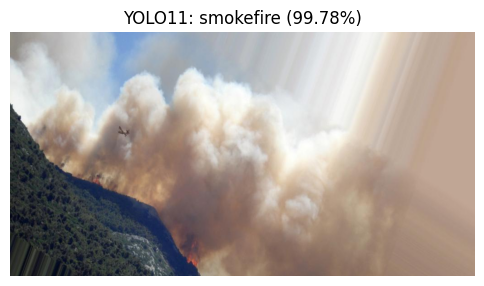

In [ ]:
if "image_path" not in globals() or not Path(str(image_path)).exists():
    try:
        from google.colab import files
        uploaded_yolo_image = files.upload()
        image_path = next(iter(uploaded_yolo_image))
    except Exception as exc:
        raise RuntimeError("Upload an image before running prediction.") from exc

if "YOLO11_BEST" not in globals() or not Path(YOLO11_BEST).exists():
    raise FileNotFoundError("YOLO11 best checkpoint not found. Run the YOLO11 training cell first.")

yolo11_classifier = YOLO(str(YOLO11_BEST))
prediction = yolo11_classifier.predict(
    source=str(image_path),
    imgsz=YOLO_IMAGE_SIZE,
    verbose=False
)[0]

predicted_idx = int(prediction.probs.top1)
predicted_label = prediction.names[predicted_idx]
confidence = float(prediction.probs.top1conf)

print("YOLO11 predicted class:", predicted_label)
print(f"Confidence: {confidence * 100:.2f}%")

with Image.open(image_path) as image:
    plt.figure(figsize=(6, 5))
    plt.imshow(image.convert("RGB"))
    plt.title(f"YOLO11: {predicted_label} ({confidence * 100:.2f}%)")
    plt.axis("off")
    plt.show()

## Final note

This additional section keeps the original EfficientNet-B0 work intact and adds YOLO classification experiments. Compare results on the same independent test set. These models classify the whole image; they do not draw boxes around fire or smoke. Object detection requires annotated bounding boxes.